# Macro Shocks and Indian Sectors
How exposed are Indian sectors (Banking, IT, FMCG, plus the Nifty 50) to macro shocks: RBI repo rate, inflation, oil and the rupee? Monthly data, Mar 2018 to Sep 2026 (99 usable months).

**To run in Google Colab:** upload `Project3_Raw_Data.xlsx` using the folder icon on the left, then Runtime > Run all.

## 1. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.stats.outliers_influence import variance_inflation_factor
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
pd.set_option("display.width", 200); pd.set_option("display.max_columns", None); pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 2. Load raw data and build monthly changes
Prices become % changes; repo rate and CPI become changes in percentage points. March 2020 gets a Covid dummy; May-Jul 2020 and Feb 2026 are dropped because the CPI series is not comparable in those months.

In [2]:
# Raw monthly data: index closes, Brent, USD/INR, repo level, CPI (as announced)
raw = pd.read_excel("Project3_Raw_Data.xlsx", sheet_name="Raw_Data").set_index("Month")
print("Months:", len(raw), "|", raw.index[0], "to", raw.index[-1])

# Levels -> changes: % change for prices, change in percentage points for repo and CPI
R = pd.DataFrame(index=raw.index)
R["N50"]  = raw.Nifty50.pct_change() * 100
R["BANK"] = raw.NiftyBank.pct_change() * 100
R["IT"]   = raw.NiftyIT.pct_change() * 100
R["FMCG"] = raw.NiftyFMCG.pct_change() * 100
R["dREPO"] = raw.Repo.diff()
R["dCPI"]  = raw.CPI.diff()
R["OIL"]   = raw.Brent.pct_change() * 100
R["FX"]    = raw.USDINR.pct_change() * 100

# Drop months with unusable CPI data; flag March 2020 (Covid crash) with a dummy
DROP = ["2020-05", "2020-06", "2020-07", "2026-02"]
R["COVID"] = (R.index == "2020-03").astype(int)
S = R.drop(index=DROP).dropna()
SECTORS = {"BANK": "Nifty Bank", "IT": "Nifty IT", "FMCG": "Nifty FMCG", "N50": "Nifty 50 (market)"}
MACRO = ["dREPO", "dCPI", "OIL", "FX"]
X = MACRO + ["COVID"]
print("Months used in regression:", len(S), "(", S.index[0], "to", S.index[-1], ")")
print(S.head())
S.to_csv("regression_data.csv")   # the 99-month sample used in the regressions

Months: 105 | 2018-01 to 2026-09
Months used in regression: 99 ( 2018-03 to 2026-09 )
           N50   BANK     IT   FMCG  dREPO   dCPI    OIL     FX  COVID
Month                                                                 
2018-03 -3.613 -3.362 -2.322 -1.457  0.000 -0.630  7.122 -0.146      0
2018-04  6.186  5.227 11.787 10.125  0.000 -0.160  7.716  2.066      0
2018-05 -0.030  5.580 -2.290  0.144  0.000  0.300  3.843  1.460      0
2018-06 -0.204 -2.196  2.367  0.526  0.250  0.290  2.153  1.528      0
2018-07  5.994  5.310  4.277  7.047  0.000  0.130 -6.336  0.000      0


## 3. Regression per sector (OLS with Newey-West HAC standard errors)
Return = constant + b1 x repo change + b2 x CPI change + b3 x oil % + b4 x USD/INR % + b5 x Covid dummy. A coefficient is treated as reliable when p < 0.10.

In [3]:
hac = lambda y, cols=X, d=S: sm.OLS(d[y], sm.add_constant(d[cols])).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
plain = lambda y, cols=X, d=S: sm.OLS(d[y], sm.add_constant(d[cols])).fit()
M = {k: hac(k) for k in SECTORS}
coef = pd.DataFrame({SECTORS[k]: M[k].params[MACRO] for k in SECTORS}).T
pval = pd.DataFrame({SECTORS[k]: M[k].pvalues[MACRO] for k in SECTORS}).T
print("R-squared:", {SECTORS[k]: round(M[k].rsquared, 3) for k in SECTORS})
print("\nCoefficients (effect on monthly return, % points):"); print(coef)
print("p-values (< 0.10 = reliable):"); print(pval)

R-squared: {'Nifty Bank': np.float64(0.378), 'Nifty IT': np.float64(0.111), 'Nifty FMCG': np.float64(0.136), 'Nifty 50 (market)': np.float64(0.387)}

Coefficients (effect on monthly return, % points):
                   dREPO   dCPI    OIL     FX
Nifty Bank         1.132 -0.283  0.052 -1.684
Nifty IT          -4.123 -0.105  0.074 -0.479
Nifty FMCG         2.995 -0.250 -0.048 -0.993
Nifty 50 (market) -1.053 -0.513  0.038 -1.309
p-values (< 0.10 = reliable):
                   dREPO  dCPI   OIL    FX
Nifty Bank         0.598 0.615 0.608 0.000
Nifty IT           0.244 0.877 0.283 0.249
Nifty FMCG         0.188 0.651 0.349 0.001
Nifty 50 (market)  0.591 0.243 0.511 0.000


## 4. Diagnostics
Durbin-Watson (autocorrelation), Breusch-Pagan (heteroskedasticity), Jarque-Bera (normality), VIF (multicollinearity).

In [4]:
# Diagnostics
Xf = sm.add_constant(S[X])
diag = pd.DataFrame({SECTORS[k]: {"R-squared": plain(k).rsquared, "Durbin-Watson": durbin_watson(plain(k).resid), "Breusch-Pagan p": het_breuschpagan(plain(k).resid, Xf)[1], "Jarque-Bera p": jarque_bera(plain(k).resid)[1]} for k in SECTORS}).T
print(diag)
print("VIF:", {c: round(variance_inflation_factor(Xf.values, i), 2) for i, c in enumerate(Xf.columns) if c != "const"})

                   R-squared  Durbin-Watson  Breusch-Pagan p  Jarque-Bera p
Nifty Bank             0.378          2.233            0.013          0.002
Nifty IT               0.111          1.902            0.698          0.977
Nifty FMCG             0.136          2.063            0.455          0.035
Nifty 50 (market)      0.387          1.981            0.103          0.218
VIF: {'dREPO': np.float64(1.33), 'dCPI': np.float64(1.04), 'OIL': np.float64(1.35), 'FX': np.float64(1.19), 'COVID': np.float64(1.84)}


## 5. Heatmap: effect of a one-standard-deviation shock
Coefficient x standard deviation of the shock puts all four shocks on a comparable scale.

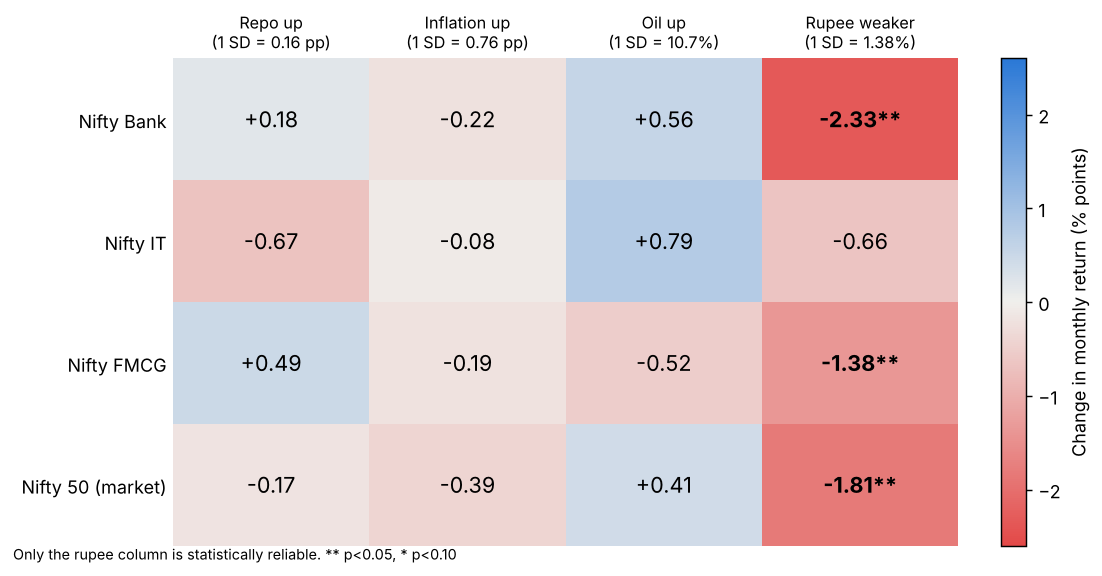

                   dREPO   dCPI    OIL     FX
Nifty Bank         0.180 -0.220  0.560 -2.330
Nifty IT          -0.670 -0.080  0.790 -0.660
Nifty FMCG         0.490 -0.190 -0.520 -1.380
Nifty 50 (market) -0.170 -0.390  0.410 -1.810


In [5]:
# Heatmap: effect of a 1-standard-deviation shock = coefficient x std dev of the shock
sd = S[MACRO].std(ddof=1)
effect = coef * sd
labels = [f"Repo up\n(1 SD = {sd.dREPO:.2f} pp)", f"Inflation up\n(1 SD = {sd.dCPI:.2f} pp)", f"Oil up\n(1 SD = {sd.OIL:.1f}%)", f"Rupee weaker\n(1 SD = {sd.FX:.2f}%)"]
star = lambda p: "**" if p < .05 else ("*" if p < .10 else "")
fig, ax = plt.subplots(figsize=(8.5, 4.4), dpi=130)
im = ax.imshow(effect.values, cmap=LinearSegmentedColormap.from_list("d", ["#e34948", "#f0efec", "#2a78d6"]), vmin=-2.6, vmax=2.6, aspect="auto")
_ = [ax.text(j, i, f"{effect.values[i,j]:+.2f}{star(pval.values[i,j])}", ha="center", va="center", fontsize=12, fontweight="bold" if star(pval.values[i,j]) else "normal") for i in range(4) for j in range(4)]
ax.set_xticks(range(4)); ax.set_xticklabels(labels, fontsize=9); ax.set_yticks(range(4)); ax.set_yticklabels(effect.index)
ax.xaxis.tick_top(); ax.tick_params(length=0)
_ = [s.set_visible(False) for s in ax.spines.values()]
fig.colorbar(im, ax=ax, fraction=0.035).set_label("Change in monthly return (% points)")
fig.text(0.01, 0.01, "Only the rupee column is statistically reliable. ** p<0.05, * p<0.10", fontsize=8)
fig.tight_layout(); fig.savefig("heatmap.png"); plt.show()
print(effect.round(2))

## 6. Stability: two sub-periods and the model without the Covid dummy

In [6]:
fmt = lambda m, v: f"{m.params[v]:+.2f} (p={m.pvalues[v]:.2f})"
view = lambda sub, cols: pd.DataFrame({SECTORS[k]: {"Repo": fmt(hac(k, cols, sub), "dREPO"), "Oil": fmt(hac(k, cols, sub), "OIL"), "Rupee": fmt(hac(k, cols, sub), "FX")} for k in SECTORS}).T
a, b = S[S.index <= "2021-12"], S[S.index >= "2022-01"]   # 2018-21 includes the Covid dummy; 2022-26 has no Covid month
print(f"2018-2021 (n={len(a)})"); print(view(a, X))
print(f"2022-2026 (n={len(b)})"); print(view(b, MACRO))
print("Full sample WITHOUT the Covid dummy:"); print(view(S, MACRO))

2018-2021 (n=43)
                             Repo             Oil           Rupee
Nifty Bank         +7.97 (p=0.22)  +0.28 (p=0.01)  -1.59 (p=0.00)
Nifty IT           +4.48 (p=0.14)  +0.11 (p=0.13)  -0.05 (p=0.91)
Nifty FMCG         +4.69 (p=0.44)  +0.04 (p=0.43)  -0.92 (p=0.01)
Nifty 50 (market)  +3.48 (p=0.43)  +0.16 (p=0.00)  -1.10 (p=0.00)
2022-2026 (n=56)
                             Repo             Oil           Rupee
Nifty Bank         -1.45 (p=0.47)  -0.13 (p=0.07)  -1.71 (p=0.01)
Nifty IT           -3.64 (p=0.32)  +0.06 (p=0.59)  -1.46 (p=0.05)
Nifty FMCG         +2.99 (p=0.37)  -0.10 (p=0.12)  -1.20 (p=0.07)
Nifty 50 (market)  -1.45 (p=0.54)  -0.04 (p=0.46)  -1.82 (p=0.00)
Full sample WITHOUT the Covid dummy:
                             Repo             Oil           Rupee
Nifty Bank         +7.86 (p=0.08)  +0.15 (p=0.16)  -2.28 (p=0.00)
Nifty IT           -0.29 (p=0.94)  +0.13 (p=0.05)  -0.82 (p=0.08)
Nifty FMCG         +4.06 (p=0.03)  -0.03 (p=0.44)  -1.09 (p=0.00)
Nifty

## 7. Stress test and historical Value at Risk
Stress test = coefficient x shock size. VaR = 5th percentile of monthly returns.

In [7]:
# Stress test = coefficient x shock size
scen = pd.DataFrame({"dREPO": [1, 0, 0, 1], "dCPI": [0, 0, 0, 1], "OIL": [0, 20, 0, 20], "FX": [0, 0, 5, 5]}, index=["A. Repo +1 pp", "B. Oil +20%", "C. Rupee 5% weaker", "D. All combined"])
allc = pd.DataFrame({SECTORS[k]: scen @ M[k].params[MACRO] for k in SECTORS})
rel = pd.DataFrame({SECTORS[k]: scen @ M[k].params[MACRO].where(M[k].pvalues[MACRO] < .10, 0) for k in SECTORS})
print("Stress test, all coefficients:"); print(allc.round(1))
print("Stress test, reliable coefficients only (p<0.10):"); print(rel.round(1))

# Historical 95% VaR = 5th percentile of monthly returns
var = pd.DataFrame({n: {"avg month %": R[k].mean(), "std dev %": R[k].std(), "95% VaR %": np.nanpercentile(R[k], 5), "worst month %": R[k].min(), "worst month": R[k].idxmin()} for k, n in SECTORS.items()}).T
var["Loss on Rs 10 lakh at 95% VaR"] = (-var["95% VaR %"].astype(float) / 100 * 1_000_000).round(0)
print(var)
coef.to_csv('coefficients.csv'); pval.to_csv('pvalues.csv'); allc.to_csv('stress_all.csv'); rel.to_csv('stress_reliable.csv'); var.to_csv('var.csv')

Stress test, all coefficients:
                    Nifty Bank  Nifty IT  Nifty FMCG  Nifty 50 (market)
A. Repo +1 pp            1.100    -4.100       3.000             -1.100
B. Oil +20%              1.000     1.500      -1.000              0.800
C. Rupee 5% weaker      -8.400    -2.400      -5.000             -6.500
D. All combined         -6.500    -5.200      -3.200             -7.300
Stress test, reliable coefficients only (p<0.10):
                    Nifty Bank  Nifty IT  Nifty FMCG  Nifty 50 (market)
A. Repo +1 pp            0.000     0.000       0.000              0.000
B. Oil +20%              0.000     0.000       0.000              0.000
C. Rupee 5% weaker      -8.400     0.000      -5.000             -6.500
D. All combined         -8.400     0.000      -5.000             -6.500
                  avg month % std dev % 95% VaR % worst month % worst month  Loss on Rs 10 lakh at 95% VaR
Nifty Bank              0.916     6.899    -8.677       -34.319     2020-03                 

## Conclusion
- The rupee is the only statistically reliable macro factor: a 1% weaker rupee is linked with about -1.7% (Bank), -1.0% (FMCG) and -1.3% (Nifty 50) in that month's return; IT is not significant.
- Repo rate, CPI and oil show no reliable effect on monthly returns in this sample.
- Banking is the most macro-fragile sector. See the README for limitations.